<a href="https://colab.research.google.com/github/NAJAM2005/flyrank-ml-internship/blob/main/work/notebooks/capstone_01_decline_prediction.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Capstone: Which declining-risk pages should an editor review first?

Lane: Refresh / Content Opportunity Scoring. Data: FlyRank internship lane datasets (pseudonymized), `ai_opportunity` cut, June-2026 example windows. All outputs are aggregate or anonymised ("Client A", never raw IDs). Claims are observed and directional, for decision-support only.


In [1]:
%pip install -q datasets pandas scikit-learn matplotlib
import os, json
import numpy as np, pandas as pd
from getpass import getpass
from huggingface_hub import login
from datasets import load_dataset

from google.colab import userdata
login(token=userdata.get("HF_TOKEN"))
os.makedirs("work/outputs/figs", exist_ok=True)
print("setup ok")

setup ok


## 1. Which lane can support a prediction?

A forward-looking label needs two consecutive time windows and a mix of declining and non-declining pages. I compared the four default lanes. A page counts as declining if impressions in the last 30 days fell more than 20% against the previous 30 days (pages with at least 100 previous-30-day impressions only).

In [2]:
lanes = ["decline_recovery", "ranking_lifecycle", "engagement_fix", "ai_opportunity"]
rows, ids = [], {}
for lane in lanes:
    x = load_dataset("FlyRank/internship-lanes", lane)["train"].to_pandas()
    two = {"impressions_last_30d", "impressions_prev_30d"} <= set(x.columns)
    r = {"lane": lane, "pages": len(x), "clients": x["client_hash_id"].nunique(),
         "has_two_windows": two, "usable_pages": np.nan, "share_declining": np.nan}
    if two:
        u = x[x["impressions_prev_30d"] >= 100]
        r["usable_pages"] = len(u)
        r["share_declining"] = round((u["impressions_last_30d"] < 0.8 * u["impressions_prev_30d"]).mean(), 3)
    rows.append(r)
    ids[lane] = (set(x["content_hash_id"]), set(x["client_hash_id"]))
    if lane == "ai_opportunity":
        raw = x.copy()
    del x

lane_table = pd.DataFrame(rows)
print(lane_table.to_string(index=False))

# do the lanes share page or client keys? (counts only)
key_rows = []
for lane in ["decline_recovery", "ranking_lifecycle", "engagement_fix"]:
    key_rows.append({"other_lane": lane,
                     "shared_pages": len(ids["ai_opportunity"][0] & ids[lane][0]),
                     "shared_clients": len(ids["ai_opportunity"][1] & ids[lane][1])})
key_overlap = pd.DataFrame(key_rows)
print("\nKey overlap with ai_opportunity:")
print(key_overlap.to_string(index=False))
del ids

             lane  pages  clients  has_two_windows  usable_pages  share_declining
 decline_recovery  56253       46             True       56253.0            1.000
ranking_lifecycle 205749       54            False           NaN              NaN
   engagement_fix  33202       44            False           NaN              NaN
   ai_opportunity  11571       33             True       11408.0            0.467

Key overlap with ai_opportunity:
       other_lane  shared_pages  shared_clients
 decline_recovery             0               0
ranking_lifecycle             0               0
   engagement_fix         10677              33


## 2. Can another lane add leak-free page features?

`engagement_fix` shares most pages with this lane (the other two lanes share none). Its 30-day traffic columns could belong to the last window, which would leak the label, so I first checked which window they match. Only columns that don't depend on the time window may be used as features.

In [3]:
ef = load_dataset("FlyRank/internship-lanes", "engagement_fix")["train"].to_pandas()
print("engagement_fix columns:")
print(list(ef.columns))

m = (raw[["content_hash_id", "impressions_last_30d", "impressions_prev_30d", "impressions_90d"]]
       .merge(ef[["content_hash_id", "impressions_30d"]].drop_duplicates("content_hash_id"),
              on="content_hash_id", how="inner"))
print("\nmatched pages:", len(m))
print("impressions_30d == last_30d:", round((m["impressions_30d"] == m["impressions_last_30d"]).mean(), 3))
print("impressions_30d == prev_30d:", round((m["impressions_30d"] == m["impressions_prev_30d"]).mean(), 3))
print("impressions_30d == 90d total:", round((m["impressions_30d"] == m["impressions_90d"]).mean(), 3))
for col in ["impressions_last_30d", "impressions_prev_30d", "impressions_90d"]:
    print(f"corr(log impressions_30d, log {col}) =",
          round(np.corrcoef(np.log1p(m["impressions_30d"]), np.log1p(m[col]))[0, 1], 3))
print("median ratio impressions_30d / last_30d:", round((m["impressions_30d"] / m["impressions_last_30d"].replace(0, np.nan)).median(), 3))
print("median ratio impressions_30d / prev_30d:", round((m["impressions_30d"] / m["impressions_prev_30d"].replace(0, np.nan)).median(), 3))

engagement_fix columns:
['client_hash_id', 'content_hash_id', 'content_type', 'main_intent', 'age_tier', 'freshness_tier', 'word_count_tier', 'char_count_tier', 'client_has_gsc', 'client_has_ga4', 'impressions_30d', 'clicks_30d', 'pageviews_30d', 'sessions_30d', 'users_30d', 'engaged_sessions_30d', 'ai_sessions_30d', 'scroll_events_30d', 'ctr_30d', 'avg_position_30d', 'engagement_rate_30d', 'scroll_rate_30d', 'ai_traffic_pct_30d', 'impression_tier', 'position_tier', 'health_score', 'needs_indexing', 'is_quick_win', 'needs_ctr_fix', 'needs_engagement_fix', 'ai_opportunity']

matched pages: 10677
impressions_30d == last_30d: 1.0
impressions_30d == prev_30d: 0.004
impressions_30d == 90d total: 0.007
corr(log impressions_30d, log impressions_last_30d) = 1.0
corr(log impressions_30d, log impressions_prev_30d) = 0.842
corr(log impressions_30d, log impressions_90d) = 0.937
median ratio impressions_30d / last_30d: 1.0
median ratio impressions_30d / prev_30d: 0.844


## 3. Label and features

**Finding:** `engagement_fix` shares 93.6% of this lane's pages, but its 30-day traffic columns equal this lane's *last* 30 days (100% exact match), so they are not used. Only its static page descriptors are: `main_intent`, `word_count_tier`, `char_count_tier`, plus `freshness_tier`, which is measured at the end of the label window and so is reported as a separate sensitivity run, not in the main set.

**Label:** 1 if impressions in the last 30 days fell more than 20% against the previous 30 days (pages with at least 100 previous-30-day impressions).
**Main features:** previous-window impressions, oldest-window impressions (90-day total minus the two later windows), momentum, a no-old-traffic flag, age tier, intent, word-count tier, character-count tier.
**Excluded:** every 90-day column, the last-30-day columns, `trend_*`, `health_score`, `is_declining`, all product flags, and the engagement_fix traffic columns.

In [4]:
STATIC = ["main_intent", "word_count_tier", "char_count_tier", "freshness_tier"]
stat = ef[["content_hash_id"] + STATIC].drop_duplicates("content_hash_id")

d = raw[raw["impressions_prev_30d"] >= 100].copy()
d["label"] = (d["impressions_last_30d"] < 0.8 * d["impressions_prev_30d"]).astype(int)
d["imp_old30"] = d["impressions_90d"] - d["impressions_last_30d"] - d["impressions_prev_30d"]
d["log_prev30"] = np.log1p(d["impressions_prev_30d"])
d["log_old30"] = np.log1p(d["imp_old30"])
d["momentum"] = d["log_prev30"] - d["log_old30"]
d["no_old_traffic"] = (d["imp_old30"] == 0).astype(int)

d = d.merge(stat, on="content_hash_id", how="left")
matched = d["main_intent"].notna().mean()
for c in STATIC:
    d[c] = d[c].fillna("unknown").astype(str)
d = d.reset_index(drop=True)

print("usable pages:", len(d), "| label rate:", round(d["label"].mean(), 3))
print("static-feature coverage:", round(matched, 3), "\n")
for c in STATIC:
    t = d.groupby(c)["label"].agg(n="size", decline_rate="mean").round(3)
    print(c); print(t.to_string(), "\n")

usable pages: 11408 | label rate: 0.467
static-feature coverage: 0.925 

main_intent
                  n  decline_rate
main_intent                      
commercial     1845         0.494
informational  6426         0.432
navigational      5         0.800
transactional  2224         0.463
unknown         908         0.663 

word_count_tier
                    n  decline_rate
word_count_tier                    
1000-2000         126         0.325
2000-3500        5712         0.376
3500+            2643         0.613
<1000               6         0.167
unknown          2921         0.518 

char_count_tier
                    n  decline_rate
char_count_tier                    
15000-25000      6045         0.381
25000+           1992         0.670
8000-15000        437         0.394
<8000              13         0.077
unknown          2921         0.518 

freshness_tier
                   n  decline_rate
freshness_tier                    
0-30            3443         0.430
181+           

In [5]:
d["in_ef"] = d["content_hash_id"].isin(ef["content_hash_id"])
print("1) in engagement_fix vs not")
print(d.groupby("in_ef").agg(n=("label", "size"), decline_rate=("label", "mean"),
                              median_prev30=("impressions_prev_30d", "median")).round(3).to_string())

inm = d[d["in_ef"]]
print("\n2) among pages IN engagement_fix: blank vs filled")
for c in ["main_intent", "word_count_tier", "freshness_tier"]:
    t = inm.groupby(inm[c] == "unknown")["label"].agg(n="size", decline_rate="mean").round(3)
    t.index = ["filled", "blank"] if len(t) == 2 else t.index
    print(c); print(t.to_string(), "\n")

1) in engagement_fix vs not
           n  decline_rate  median_prev30
in_ef                                    
False    858         0.669         2788.0
True   10550         0.450         4091.0

2) among pages IN engagement_fix: blank vs filled
main_intent
            n  decline_rate
filled  10500          0.45
blank      50          0.56 

word_count_tier
           n  decline_rate
filled  8487         0.449
blank   2063         0.456 

freshness_tier
                    n  decline_rate
freshness_tier                     
False           10550          0.45 



In [6]:
out = d[~d["in_ef"]]
inn = d[d["in_ef"]]
print("pages outside engagement_fix:", len(out), "| inside:", len(inn))
print("share with ZERO last-30-day impressions: outside", round((out["impressions_last_30d"] == 0).mean(), 3),
      "| inside", round((inn["impressions_last_30d"] == 0).mean(), 3))
print("median last/prev impressions ratio: outside",
      round((out["impressions_last_30d"] / out["impressions_prev_30d"]).median(), 3),
      "| inside", round((inn["impressions_last_30d"] / inn["impressions_prev_30d"]).median(), 3))

pages outside engagement_fix: 858 | inside: 10550
share with ZERO last-30-day impressions: outside 0.006 | inside 0.0
median last/prev impressions ratio: outside 0.592 | inside 0.844


In [7]:
dm = d[d["in_ef"]].copy().reset_index(drop=True)

merge_maps = {
    "main_intent":     {"navigational": "other", "unknown": "other"},
    "word_count_tier": {"<1000": "<2000", "1000-2000": "<2000", "unknown": "unknown"},
    "char_count_tier": {"<8000": "<15000", "8000-15000": "<15000", "unknown": "unknown"},
    "freshness_tier":  {"181+": "91+", "91-180": "91+"},
}
for c, mp in merge_maps.items():
    dm[c] = dm[c].replace(mp)

print("main analysis sample:", len(dm), "| label rate:", round(dm["label"].mean(), 3),
      "| clients:", dm["client_hash_id"].nunique())
for c in ["main_intent", "word_count_tier", "char_count_tier", "freshness_tier"]:
    print("\n" + c)
    print(dm.groupby(c)["label"].agg(n="size", decline_rate="mean").round(3).to_string())

cs = dm.groupby("client_hash_id").size()
print("\nclients with >= 100 pages:", int((cs >= 100).sum()), "of", len(cs))
big = cs[cs >= 100].sort_values(ascending=False)
print("page counts of those clients:", big.tolist())

main analysis sample: 10550 | label rate: 0.45 | clients: 29

main_intent
                  n  decline_rate
main_intent                      
commercial     1845         0.494
informational  6426         0.432
other            55         0.582
transactional  2224         0.463

word_count_tier
                    n  decline_rate
word_count_tier                    
2000-3500        5712         0.376
3500+            2643         0.613
<2000             132         0.318
unknown          2063         0.456

char_count_tier
                    n  decline_rate
char_count_tier                    
15000-25000      6045         0.381
25000+           1992         0.670
<15000            450         0.384
unknown          2063         0.456

freshness_tier
                   n  decline_rate
freshness_tier                    
0-30            3443         0.430
31-90           3890         0.367
91+             3217         0.573

clients with >= 100 pages: 10 of 29
page counts of those clients

In [8]:
big_ids = dm.groupby("client_hash_id").size()
big_ids = big_ids[big_ids >= 100].sort_values(ascending=False).index.tolist()
letter = {c: f"Client {chr(65 + i)}" for i, c in enumerate(big_ids)}

def compare(col, hi, lo):
    rows = []
    for c in big_ids:
        g = dm[dm["client_hash_id"] == c]
        a, b = g[g[col].isin(hi)], g[g[col].isin(lo)]
        if len(a) >= 10 and len(b) >= 10:
            rows.append({"client": letter[c], "n_hi": len(a), "rate_hi": a["label"].mean(),
                         "n_lo": len(b), "rate_lo": b["label"].mean()})
    t = pd.DataFrame(rows)
    t["diff"] = t["rate_hi"] - t["rate_lo"]
    print(f"{col}: {hi} vs {lo}")
    print(t.round(3).to_string(index=False))
    print(f"-> higher in {int((t['diff'] > 0).sum())} of {len(t)} clients\n")

compare("word_count_tier", ["3500+"], ["2000-3500"])
compare("char_count_tier", ["25000+"], ["15000-25000"])
compare("freshness_tier", ["91+"], ["0-30", "31-90"])

# is "unknown" word count concentrated in particular clients?
unk = dm.groupby("client_hash_id")["word_count_tier"].apply(lambda s: (s == "unknown").mean())
print("clients with >50% unknown word count:", int((unk > 0.5).sum()), "of", len(unk))

word_count_tier: ['3500+'] vs ['2000-3500']
  client  n_hi  rate_hi  n_lo  rate_lo   diff
Client A    43    0.326  1937    0.421 -0.095
Client B  2480    0.617   971    0.439  0.179
Client C    46    0.326   891    0.467 -0.141
-> higher in 1 of 3 clients

char_count_tier: ['25000+'] vs ['15000-25000']
  client  n_hi  rate_hi  n_lo  rate_lo   diff
Client A    38    0.342  1841    0.416 -0.074
Client B  1856    0.678  1595    0.438  0.240
Client C    36    0.306   840    0.456 -0.150
-> higher in 1 of 3 clients

freshness_tier: ['91+'] vs ['0-30', '31-90']
  client  n_hi  rate_hi  n_lo  rate_lo   diff
Client A  1092    0.409  2833    0.458 -0.049
Client B  2048    0.664  1404    0.427  0.237
Client D    34    0.206   648    0.176  0.030
-> higher in 2 of 3 clients

clients with >50% unknown word count: 2 of 29


## 4. Models, baseline, and per-client validation

All models use leave-one-client-out validation: for each client, train on every other client and score the held-out one. The headline metric is the mean per-client AUC over clients with at least 100 usable pages (pooled AUC would partly measure which client a page belongs to, because decline rates range from about 17% to 79% across clients). Baseline: a transparent rule combining an age flag (181+ days) and demand (previous-window impressions). Planned comparisons, fixed before seeing results: age only; old-window features + age; + static features (intent, word count, character count); + freshness tier (sensitivity). Every comparison is also reported without the largest-contribution client.

In [9]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import roc_auc_score

NUM_OLD = ["log_prev30", "log_old30", "momentum", "no_old_traffic"]
AGE = ["content_age_tier"]
STATF = ["main_intent", "word_count_tier", "char_count_tier"]
sets = {
    "age_only": ([], AGE),
    "old_window+age": (NUM_OLD, AGE),
    "old_window+age+static": (NUM_OLD, AGE + STATF),
    "+freshness (sensitivity)": (NUM_OLD, AGE + STATF + ["freshness_tier"]),
}

def loco(num, cat):
    s = pd.Series(np.nan, index=dm.index)
    for c in dm["client_hash_id"].unique():
        te = dm["client_hash_id"] == c
        tf = []
        if num: tf.append(("num", StandardScaler(), num))
        if cat: tf.append(("cat", OneHotEncoder(handle_unknown="ignore"), cat))
        m = Pipeline([("pre", ColumnTransformer(tf, sparse_threshold=0)),
                      ("clf", HistGradientBoostingClassifier(max_depth=3, learning_rate=0.05,
                                                             max_iter=150, random_state=0))])
        m.fit(dm.loc[~te, num + cat], dm.loc[~te, "label"])
        s[te] = m.predict_proba(dm.loc[te, num + cat])[:, 1]
    return s

stale = dm["content_age_tier"].isin(["181-365", "365+"]).astype(float)
dm["score_baseline"] = 0.6 * stale + 0.4 * dm["log_prev30"].rank(pct=True)
for name, (num, cat) in sets.items():
    dm["score_" + name] = loco(num, cat)
    print("done:", name)

cols = ["baseline"] + list(sets)
rows = []
for c in big_ids:
    g = dm[dm["client_hash_id"] == c]
    if g["label"].nunique() == 2:
        r = {"client": letter[c], "n": len(g), "label_rate": round(g["label"].mean(), 3)}
        for k in cols:
            r[k] = roc_auc_score(g["label"], g["score_" + k])
        rows.append(r)
pc = pd.DataFrame(rows)
print("\nPer-client AUC (clients with >= 100 pages):")
print(pc.round(3).to_string(index=False))

def summ(p, label):
    out = pd.DataFrame({"mean_AUC": p[cols].mean(), "clients>0.5": (p[cols] > 0.5).sum()}).round(3)
    out["clients>0.5"] = out["clients>0.5"].astype(int).astype(str) + "/" + str(len(p))
    print(f"\n{label}"); print(out.to_string())
summ(pc, "All reported clients:")
summ(pc[pc["client"] != "Client B"], "Excluding Client B from evaluation:")

rng = np.random.default_rng(0)
def boot(a, b, p):
    diff = (p[a] - p[b]).values
    bs = np.array([rng.choice(diff, len(diff), replace=True).mean() for _ in range(5000)])
    lo, hi = np.percentile(bs, [2.5, 97.5])
    print(f"{a} minus {b}: {diff.mean():+.3f} (95% CI {lo:+.3f} to {hi:+.3f}), higher in {(diff > 0).sum()}/{len(diff)}")
print("\nPaired differences, all clients:")
boot("old_window+age", "baseline", pc)
boot("old_window+age+static", "old_window+age", pc)
boot("old_window+age+static", "baseline", pc)
print("\nPaired differences, excluding Client B:")
p2 = pc[pc["client"] != "Client B"]
boot("old_window+age", "baseline", p2)
boot("old_window+age+static", "old_window+age", p2)
boot("old_window+age+static", "baseline", p2)

done: age_only
done: old_window+age
done: old_window+age+static
done: +freshness (sensitivity)

Per-client AUC (clients with >= 100 pages):
  client    n  label_rate  baseline  age_only  old_window+age  old_window+age+static  +freshness (sensitivity)
Client A 3925       0.445     0.514     0.468           0.516                  0.507                     0.521
Client B 3452       0.567     0.601     0.590           0.554                  0.614                     0.618
Client C  938       0.459     0.510     0.556           0.571                  0.578                     0.578
Client D  682       0.177     0.656     0.469           0.475                  0.485                     0.563
Client E  457       0.411     0.471     0.498           0.525                  0.513                     0.522
Client F  314       0.172     0.576     0.570           0.637                  0.607                     0.585
Client G  146       0.240     0.632     0.638           0.546                  0.56

In [10]:
print("Added check (not in the original plan): sensitivity run vs static model, and vs baseline")
boot("+freshness (sensitivity)", "old_window+age+static", pc)
boot("+freshness (sensitivity)", "baseline", pc)

# within-client lift: decline rate in the top 20% by score minus the client's own base rate
def lift_table(frac=0.20):
    out = {k: [] for k in cols}
    for c in big_ids:
        g = dm[dm["client_hash_id"] == c]
        n = max(int(len(g) * frac), 1)
        for k in cols:
            top = g.sort_values("score_" + k, ascending=False).head(n)
            out[k].append(top["label"].mean() - g["label"].mean())
    return pd.DataFrame(out, index=[letter[c] for c in big_ids])

lt = lift_table()
print("\nTop-20% decline rate minus the client's own base rate (percentage points):")
print((lt * 100).round(1).to_string())
print("\nmean lift (pp) and clients with positive lift:")
print(pd.DataFrame({"mean_lift_pp": (lt.mean() * 100).round(1),
                    "clients>0": (lt > 0).sum().astype(int).astype(str) + "/" + str(len(lt))}).to_string())

Added check (not in the original plan): sensitivity run vs static model, and vs baseline
+freshness (sensitivity) minus old_window+age+static: +0.022 (95% CI -0.013 to +0.058), higher in 7/10
+freshness (sensitivity) minus baseline: +0.028 (95% CI -0.024 to +0.076), higher in 8/10

Top-20% decline rate minus the client's own base rate (percentage points):
          baseline  age_only  old_window+age  old_window+age+static  +freshness (sensitivity)
Client A      -0.8      -2.0             0.8                   -1.9                      -2.0
Client B       8.6      12.1             9.1                    7.6                       7.3
Client C      -1.6       1.1             7.0                    3.2                      14.5
Client D      10.2      -7.4            -0.8                    2.1                       5.1
Client E       0.6      -1.6            10.5                    5.0                      10.5
Client F       2.2       3.8            13.4                   10.2           

### 4b. Decision metrics: lost impressions captured, and a persistence check

AUC ranks all pages equally, but an editor has a review budget and a lost impression on a 10,000-impression page matters more than on a 100-impression page. This section measures the share of each client's lost impressions found in its top 20% of pages, adds two rankers an editor would actually use (biggest pages first; P(decline) x impressions), and checks whether an earlier fall predicts a later one.

Share of each client's lost impressions captured by reviewing its top 20% of pages:
          random  baseline  age_only  old_window+age  old_window+age+static  +freshness (sensitivity)  demand_only  expected_loss  oracle
client                                                                                                                                   
Client A    20.0      44.0      18.6            15.3                   21.2                      17.5         55.7           53.6    85.6
Client B    20.0      45.8      28.4            17.0                   10.3                      10.5         60.3           60.5    75.1
Client C    20.0      55.5      24.9            17.0                   20.1                      28.9         56.4           56.4    80.2
Client D    20.0      67.0       6.1            24.1                   24.1                      26.8         67.0           69.6   100.0
Client E    20.0      44.4      10.2            25.5                   24.9             

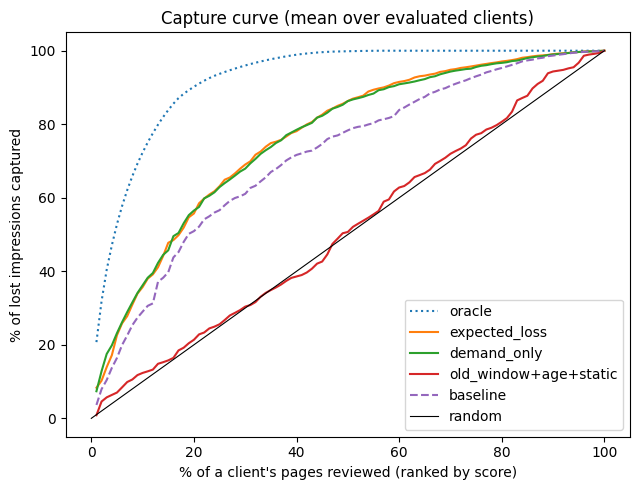


Persistence check (pages with >= 100 old-window impressions):
  client    n  decline_rate_if_earlier_fall  decline_rate_otherwise  AUC_of_-momentum   diff
Client A 3849                         0.475                   0.438             0.505  0.037
Client B 3345                         0.534                   0.619             0.447 -0.085
Client C  781                         0.539                   0.471             0.532  0.068
Client D  681                         0.120                   0.233             0.381 -0.113
Client E  457                         0.415                   0.403             0.546  0.012
Client F  279                         0.360                   0.157             0.652  0.203
Client G  141                         0.120                   0.267             0.454 -0.147
Client H  127                         0.690                   0.429             0.648  0.261
Client I  108                         0.160                   0.265             0.483 -0.105
Client 

In [11]:
# ===== 4b. Decision metrics: how many LOST IMPRESSIONS does the review budget capture? + persistence check =====
import matplotlib.pyplot as plt
from sklearn.metrics import roc_auc_score

dm["lost_imp"] = np.where(dm["label"] == 1, dm["impressions_prev_30d"] - dm["impressions_last_30d"], 0)

# two extra rankers that match how an editor actually works
dm["score_demand_only"] = dm["impressions_prev_30d"].astype(float)                      # "just review the biggest pages"
dm["score_expected_loss"] = dm["score_old_window+age+static"] * dm["impressions_prev_30d"]  # P(decline) x impressions at stake
rank_cols = cols + ["demand_only", "expected_loss"]

def capture(g, score_col, frac):
    n = max(int(len(g) * frac), 1)
    top = g.sort_values(score_col, ascending=False).head(n)
    return top["lost_imp"].sum() / g["lost_imp"].sum()

FRAC = 0.20
rows = []
for c in big_ids:
    g = dm[dm["client_hash_id"] == c]
    if g["lost_imp"].sum() == 0:
        continue
    r = {"client": letter[c], "n": len(g), "random": FRAC}
    for k in rank_cols:
        r[k] = capture(g, "score_" + k, FRAC)
    r["oracle"] = capture(g, "lost_imp", FRAC)          # best any ranker could do
    rows.append(r)
cap = pd.DataFrame(rows)
print(f"Share of each client's lost impressions captured by reviewing its top {FRAC:.0%} of pages:")
print((cap.set_index("client").drop(columns="n") * 100).round(1).to_string())
print("\nMean capture (%):")
print((cap.drop(columns=["client", "n"]).mean() * 100).round(1).to_string())

rng_c = np.random.default_rng(1)
def boot_cap(a, b, p):
    diff = (p[a] - p[b]).values
    bs = np.array([rng_c.choice(diff, len(diff), replace=True).mean() for _ in range(5000)])
    lo, hi = np.percentile(bs, [2.5, 97.5])
    print(f"{a} minus {b}: {diff.mean()*100:+.1f}pp (95% CI {lo*100:+.1f} to {hi*100:+.1f}), higher in {(diff > 0).sum()}/{len(diff)}")
print("\nPaired differences in capture (percentage points):")
boot_cap("demand_only", "baseline", cap)
boot_cap("expected_loss", "demand_only", cap)
boot_cap("expected_loss", "old_window+age+static", cap)
boot_cap("expected_loss", "baseline", cap)

# capture curve: cumulative share of lost impressions vs share of pages reviewed (mean over clients)
grid = np.linspace(0.01, 1, 100)
def curve(g, sc):
    v = g.sort_values(sc, ascending=False)["lost_imp"].to_numpy()
    cum = np.cumsum(v) / v.sum()
    x = np.arange(1, len(v) + 1) / len(v)
    return np.interp(grid, x, cum)

curves = {}
for k in ["baseline", "old_window+age+static", "demand_only", "expected_loss"]:
    curves[k] = np.mean([curve(dm[dm["client_hash_id"] == c], "score_" + k)
                         for c in big_ids if dm.loc[dm["client_hash_id"] == c, "lost_imp"].sum() > 0], axis=0)
curves["oracle"] = np.mean([curve(dm[dm["client_hash_id"] == c], "lost_imp")
                            for c in big_ids if dm.loc[dm["client_hash_id"] == c, "lost_imp"].sum() > 0], axis=0)
fig, ax = plt.subplots(figsize=(6.5, 5))
for k, ls in [("oracle", ":"), ("expected_loss", "-"), ("demand_only", "-"), ("old_window+age+static", "-"), ("baseline", "--")]:
    ax.plot(grid * 100, curves[k] * 100, ls, label=k)
ax.plot([0, 100], [0, 100], color="k", lw=0.8, label="random")
ax.set_xlabel("% of a client's pages reviewed (ranked by score)"); ax.set_ylabel("% of lost impressions captured")
ax.set_title("Capture curve (mean over evaluated clients)"); ax.legend(); plt.tight_layout()
plt.savefig("work/outputs/figs/capture_curve.png", dpi=150); plt.show()
cap.round(4).to_csv("work/outputs/capture_top20_per_client.csv", index=False)

# persistence check: does an EARLIER fall (old -> prev window) predict the LATER one (prev -> last)?
dm["earlier_fall"] = (dm["impressions_prev_30d"] < 0.8 * dm["imp_old30"]).astype(int)
sub = dm[dm["imp_old30"] >= 100]
rows = []
for c in big_ids:
    g = sub[sub["client_hash_id"] == c]
    if len(g) >= 50 and g["label"].nunique() == 2 and g["earlier_fall"].nunique() == 2:
        rows.append({"client": letter[c], "n": len(g),
                     "decline_rate_if_earlier_fall": g.loc[g["earlier_fall"] == 1, "label"].mean(),
                     "decline_rate_otherwise": g.loc[g["earlier_fall"] == 0, "label"].mean(),
                     "AUC_of_-momentum": roc_auc_score(g["label"], -g["momentum"])})
pers = pd.DataFrame(rows)
pers["diff"] = pers["decline_rate_if_earlier_fall"] - pers["decline_rate_otherwise"]
print("\nPersistence check (pages with >= 100 old-window impressions):")
print(pers.round(3).to_string(index=False))
print(f"-> later decline more likely after an earlier fall in {(pers['diff'] > 0).sum()} of {len(pers)} clients; "
      f"mean AUC of -momentum = {pers['AUC_of_-momentum'].mean():.3f}")
pers.round(4).to_csv("work/outputs/persistence_check.csv", index=False)


### 4c. Selection sensitivity: keep the 858 excluded pages

The main sample drops pages that are not in `engagement_fix`. This re-runs the baseline and the main model with them included (static features set to unknown) on the same evaluated clients.

In [12]:
# ===== 4c. Selection sensitivity: put the 858 excluded pages back =====
# The main sample drops pages that are not in engagement_fix (they decline more: 66.9% vs 45.0%).
# Here they stay in, with static features = "unknown". If the conclusions hold, the exclusion is not driving them.
df_full = d.copy().reset_index(drop=True)
for c_, mp in merge_maps.items():
    df_full[c_] = df_full[c_].replace(mp)

def loco_df(df, num, cat):
    s = pd.Series(np.nan, index=df.index)
    for c in df["client_hash_id"].unique():
        te = df["client_hash_id"] == c
        tf = []
        if num: tf.append(("num", StandardScaler(), num))
        if cat: tf.append(("cat", OneHotEncoder(handle_unknown="ignore"), cat))
        m = Pipeline([("pre", ColumnTransformer(tf, sparse_threshold=0)),
                      ("clf", HistGradientBoostingClassifier(max_depth=3, learning_rate=0.05,
                                                             max_iter=150, random_state=0))])
        m.fit(df.loc[~te, num + cat], df.loc[~te, "label"])
        s[te] = m.predict_proba(df.loc[te, num + cat])[:, 1]
    return s

stale_f = df_full["content_age_tier"].isin(["181-365", "365+"]).astype(float)
df_full["score_baseline"] = 0.6 * stale_f + 0.4 * df_full["log_prev30"].rank(pct=True)
df_full["score_static"] = loco_df(df_full, NUM_OLD, AGE + STATF)

rows = []
for c in big_ids:                                  # same 10 evaluated clients as the main analysis
    g = df_full[df_full["client_hash_id"] == c]
    if g["label"].nunique() == 2:
        rows.append({"client": letter[c], "n_full": len(g),
                     "baseline_full": roc_auc_score(g["label"], g["score_baseline"]),
                     "static_full": roc_auc_score(g["label"], g["score_static"])})
sens = pd.DataFrame(rows).merge(pc[["client", "baseline", "old_window+age+static"]], on="client")
sens = sens.rename(columns={"baseline": "baseline_main", "old_window+age+static": "static_main"})
print("AUC on the same clients: main sample vs sample that keeps the 858 excluded pages")
print(sens.round(3).to_string(index=False))
print("\nMean AUC:", sens[["baseline_main", "baseline_full", "static_main", "static_full"]].mean().round(3).to_dict())
print("Label rate: main", round(dm["label"].mean(), 3), "| full", round(df_full["label"].mean(), 3))
sens.round(4).to_csv("work/outputs/selection_sensitivity.csv", index=False)


AUC on the same clients: main sample vs sample that keeps the 858 excluded pages
  client  n_full  baseline_full  static_full  baseline_main  static_main
Client A    4015          0.508        0.515          0.514        0.507
Client B    3499          0.600        0.625          0.601        0.614
Client C     959          0.500        0.572          0.510        0.578
Client D     717          0.630        0.590          0.656        0.485
Client E     478          0.476        0.554          0.471        0.513
Client F     314          0.576        0.636          0.576        0.607
Client G     155          0.617        0.588          0.632        0.569
Client H     142          0.542        0.665          0.563        0.612
Client I     124          0.568        0.536          0.573        0.534
Client J     104          0.501        0.677          0.510        0.649

Mean AUC: {'baseline_main': 0.561, 'baseline_full': 0.552, 'static_main': 0.567, 'static_full': 0.596}
Label rate: 

## 5. Segments, value at stake, and concentration

Segments combine page age tier and demand tier (terciles of previous-window impressions). For each segment: decline rate, the number of clients in which the segment declines more than that client's own average (clients with at least 100 pages and at least 10 pages in the segment), expected impressions lost per page, and its share of all lost impressions, also with the largest-loss client removed. Segment findings are in-sample and directional; action labels use conventions (a 5-point lift and a majority of clients), not statistical tests.

In [13]:
dm["lost_imp"] = np.where(dm["label"] == 1, dm["impressions_prev_30d"] - dm["impressions_last_30d"], 0)
dm["demand_tier"] = pd.qcut(dm["log_prev30"], 3, labels=["low", "mid", "high"])
dm["segment"] = dm["content_age_tier"].astype(str) + " | " + dm["demand_tier"].astype(str) + " demand"
base = dm["label"].mean()
tot = dm["lost_imp"].sum()

own = dm.groupby("client_hash_id")["label"].agg(n="size", rate="mean")
own = own[own["n"] >= 100]
top_loss_client = dm.groupby("client_hash_id")["lost_imp"].sum().idxmax()
dd = dm[dm["client_hash_id"] != top_loss_client]
tot2 = dd["lost_imp"].sum()

rows = []
for s, g in dm.groupby("segment", observed=True):
    if len(g) < 100:
        continue
    diffs = [gc["label"].mean() - own.loc[c, "rate"]
             for c, gc in g.groupby("client_hash_id") if c in own.index and len(gc) >= 10]
    g2 = dd[dd["segment"] == s]
    rows.append({"segment": s, "n_pages": len(g), "decline_rate": g["label"].mean(),
                 "lift_pp": (g["label"].mean() - base) * 100,
                 "clients_above_own": f"{sum(x > 0 for x in diffs)}/{len(diffs)}",
                 "loss_per_page": g["lost_imp"].mean(),
                 "loss_share": g["lost_imp"].sum() / tot,
                 "loss_share_without_top_client": g2["lost_imp"].sum() / tot2})
seg2 = pd.DataFrame(rows).sort_values("loss_share", ascending=False).reset_index(drop=True)
print(f"base rate {base:.3f} | pages {len(dm)}")
print(seg2.round(3).to_string(index=False))

s_ = dm["lost_imp"].sort_values(ascending=False)
print("\nConcentration of lost impressions:")
for p in (0.01, 0.05, 0.10):
    print(f"  top {p:.0%} of pages hold {s_.head(int(len(s_) * p)).sum() / tot:.1%}")
cl = (dm.groupby("client_hash_id")["lost_imp"].sum().sort_values(ascending=False) / tot)
print("  share of total loss by client (top 5):", [f"{v:.1%}" for v in cl.head(5)])
print("  top-loss client holds", f"{(dm['client_hash_id'] == top_loss_client).mean():.1%}", "of pages")

base rate 0.450 | pages 10550
              segment  n_pages  decline_rate  lift_pp clients_above_own  loss_per_page  loss_share  loss_share_without_top_client
 91-180 | high demand     1548         0.413   -3.735               7/9       3007.136       0.328                          0.336
181-365 | high demand     1003         0.476    2.543               3/4       3197.878       0.226                          0.218
   365+ | high demand      827         0.398   -5.232               3/3       2857.832       0.166                          0.079
 181-365 | mid demand     1306         0.520    6.977               2/4        908.894       0.084                          0.118
  91-180 | mid demand     1325         0.457    0.722               7/9        849.308       0.079                          0.120
 181-365 | low demand     1417         0.581   13.066               3/4        345.733       0.035                          0.058
    365+ | mid demand      603         0.352   -9.857       

### 5b. Segments with within-client demand tiers

Pooled demand terciles partly measure client size. Here every client's pages are split into its own low / mid / high demand thirds.

In [14]:
# ===== 5b. Segments with WITHIN-client demand tiers (removes the "high demand = big client" confound) =====
r_ = dm.groupby("client_hash_id")["log_prev30"].rank(pct=True, method="first")
dm["demand_tier_w"] = np.select([r_ <= 1/3, r_ <= 2/3], ["low", "mid"], default="high")
dm["segment_w"] = dm["content_age_tier"].astype(str) + " | " + dm["demand_tier_w"] + " demand (within client)"

own_ = dm.groupby("client_hash_id")["label"].agg(n="size", rate="mean"); own_ = own_[own_["n"] >= 100]
top_c = dm.groupby("client_hash_id")["lost_imp"].sum().idxmax()
dd_ = dm[dm["client_hash_id"] != top_c]
rows = []
for s, g in dm.groupby("segment_w"):
    if len(g) < 100:
        continue
    diffs = [gc["label"].mean() - own_.loc[c, "rate"] for c, gc in g.groupby("client_hash_id")
             if c in own_.index and len(gc) >= 10]
    g2 = dd_[dd_["segment_w"] == s]
    rows.append({"segment": s, "n_pages": len(g), "decline_rate": g["label"].mean(),
                 "lift_pp": (g["label"].mean() - dm["label"].mean()) * 100,
                 "clients_above_own": f"{sum(x > 0 for x in diffs)}/{len(diffs)}",
                 "loss_share": g["lost_imp"].sum() / dm["lost_imp"].sum(),
                 "loss_share_without_top_client": g2["lost_imp"].sum() / dd_["lost_imp"].sum()})
seg_w = pd.DataFrame(rows).sort_values("loss_share", ascending=False).reset_index(drop=True)
print(seg_w.round(3).to_string(index=False))
seg_w.round(4).to_csv("work/outputs/segments_within_client.csv", index=False)


                              segment  n_pages  decline_rate  lift_pp clients_above_own  loss_share  loss_share_without_top_client
 91-180 | high demand (within client)     1543         0.444   -0.620               7/9       0.324                          0.367
181-365 | high demand (within client)     1235         0.547    9.642               3/4       0.249                          0.290
   365+ | high demand (within client)      595         0.385   -6.527               2/3       0.144                          0.067
  91-180 | mid demand (within client)     1351         0.435   -1.491               5/9       0.082                          0.091
 181-365 | mid demand (within client)     1305         0.515    6.480               1/4       0.071                          0.074
    365+ | mid demand (within client)      599         0.377   -7.285               2/3       0.038                          0.016
 181-365 | low demand (within client)     1186         0.533    8.274              

### Ranked recommendations (in-sample, directional)

| Priority | Segment (within-client demand) | Evidence | Action label |
|---|---|---|---|
| 1 | 181–365 days, high demand | 54.7% decline (+9.6pp); 24.9% of lost impressions (29.0% without top client); above own rate in 3/4 clients | REVIEW_FIRST (thin client evidence) |
| 2 | 91–180 days, high demand | Average risk (44.4%) but 32.4% of lost impressions (36.7% without top client); above own rate in 7/9 | REVIEW_FIRST (for volume at stake; rank pages by impressions) |
| 3 | 181–365 days, low demand | 53.3% decline (+8.3pp) but 2.4% of loss | BATCH_REVIEW |
| 4 | 365+ days, high demand | 14.4% of loss falls to 6.7% without top client; 38.5% decline rate | MONITOR (WATCH_HIGH_VALUE for pages inside the review budget; client-dependent) |
| 5 | Other mid-age and older segments | Mixed or small | MONITOR |
| 6 | 31–90 days, any demand | 17–24pp below base; below own rate in 0/3, 0/4, 0/5 clients | LOW_PRIORITY |

Action labels use conventions (a lift of about 5 points and a majority of clients), not statistical tests. No claim is made that refreshing a page changes its traffic. Figures come from the within-client segments in section 5b.

### 5c. Page-level ranked action list with reason codes

Turns the out-of-fold scores into a ranked list per client (impressions at risk = P(decline) x previous-window impressions), with reason codes and an action label. Published outputs are anonymised: no page or client ids, impressions in bands, 15 example rows only. The reason-code check reports whether each code really goes with more decline.

In [15]:
# ===== 5c. Page-level ranked action list with reason codes (anonymised) =====
ranked = dm.copy()
ranked["risk_score"] = ranked["score_old_window+age+static"]          # out-of-fold (leave-one-client-out); a ranking score, NOT a calibrated probability
ranked["impr_at_risk"] = ranked["risk_score"] * ranked["impressions_prev_30d"]
ranked["client_label"] = ranked["client_hash_id"].map(letter).fillna("Other client")
g_ = ranked.groupby("client_hash_id")["impr_at_risk"]
ranked["rank_in_client"] = g_.rank(ascending=False, method="first").astype(int)
ranked["in_review_budget"] = (ranked["rank_in_client"] / g_.transform("size")) <= 0.20   # top 20% per client

age = ranked["content_age_tier"].astype(str)
flags = pd.DataFrame({
    "HIGH_DEMAND": ranked["demand_tier_w"] == "high",
    "AGING_91_365": age.isin(["91-180", "181-365"]),
    "NEGATIVE_MOMENTUM": (ranked["imp_old30"] >= 100) & (ranked["momentum"] < np.log(0.8)),
    "LONG_CONTENT_WEAK_EVIDENCE": ranked["word_count_tier"] == "3500+",   # only higher in 1 of 3 clients
})
ranked["reason_codes"] = [("|".join(flags.columns[row]) or "NONE") for row in flags.to_numpy()]
ranked["action"] = np.select(
    [age.isin(["91-180", "181-365"]) & (ranked["demand_tier_w"] == "high"),
     (age == "181-365") & (ranked["demand_tier_w"] == "low"),
     age.isin(["0-30", "31-90"])],
    ["REVIEW_FIRST", "BATCH_REVIEW", "LOW_PRIORITY"], default="MONITOR")
# big pages that sit in the review budget should not be labelled plain MONITOR
ranked.loc[ranked["in_review_budget"] & (ranked["action"] == "MONITOR"), "action"] = "WATCH_HIGH_VALUE"

# does each reason code actually go with more decline? (in-sample, directional)
chk = []
for k in flags.columns:
    f = flags[k]
    chk.append({"reason_code": k, "n_with": int(f.sum()), "decline_rate_with": ranked.loc[f, "label"].mean(),
                "decline_rate_without": ranked.loc[~f, "label"].mean(),
                "share_of_lost_impr_with": ranked.loc[f, "lost_imp"].sum() / ranked["lost_imp"].sum()})
reason_check = pd.DataFrame(chk)
print(reason_check.round(3).to_string(index=False))

act = ranked.groupby("action").agg(pages=("label", "size"), decline_rate=("label", "mean"),
                                   share_of_lost_impr=("lost_imp", lambda s: s.sum() / ranked["lost_imp"].sum()))
print("\n", act.round(3).to_string())
bud = ranked[ranked["in_review_budget"]]
print(f"\nIn the top-20%-per-client review budget: {len(bud)} pages hold "
      f"{bud['lost_imp'].sum() / ranked['lost_imp'].sum():.1%} of all lost impressions")

# public-safe outputs: NO page/client ids, impressions as bands, only a small sample of rows
bands = pd.cut(ranked["impr_at_risk"], [-1, 500, 2000, 10000, np.inf], labels=["<500", "500-2k", "2k-10k", "10k+"])
ranked["impr_at_risk_band"] = bands.astype(str)
cols_out = ["client_label", "rank_in_client", "in_review_budget", "content_age_tier", "demand_tier_w",
            "main_intent", "word_count_tier", "risk_score", "impr_at_risk_band", "reason_codes", "action"]
sample = (ranked[ranked["client_label"] != "Other client"]
          .sort_values(["client_label", "rank_in_client"]).groupby("client_label").head(3)[cols_out]
          .round({"risk_score": 2}))
print("\nExample of the ranked action list (top 15, anonymised):")
print(sample.to_string(index=False))
sample.to_csv("work/outputs/ranked_pages_sample.csv", index=False)
reason_check.round(4).to_csv("work/outputs/reason_code_check.csv", index=False)
act.round(4).to_csv("work/outputs/action_summary.csv")
# NOTE: `ranked` itself still holds content_hash_id. Never save it to the repo.

               reason_code  n_with  decline_rate_with  decline_rate_without  share_of_lost_impr_with
               HIGH_DEMAND    3528              0.461                 0.445                    0.730
              AGING_91_365    7640              0.477                 0.379                    0.770
         NEGATIVE_MOMENTUM    3895              0.466                 0.441                    0.297
LONG_CONTENT_WEAK_EVIDENCE    2643              0.613                 0.396                    0.203

                   pages  decline_rate  share_of_lost_impr
action                                                   
BATCH_REVIEW       1186         0.533               0.024
LOW_PRIORITY        779         0.249               0.027
MONITOR            5545         0.445               0.278
REVIEW_FIRST       2778         0.490               0.573
WATCH_HIGH_VALUE    262         0.374               0.098

In the top-20%-per-client review budget: 2098 pages hold 56.4% of all lost impressions

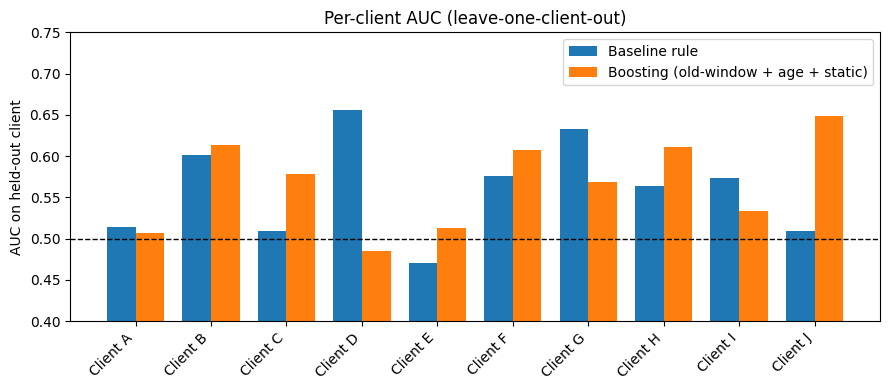

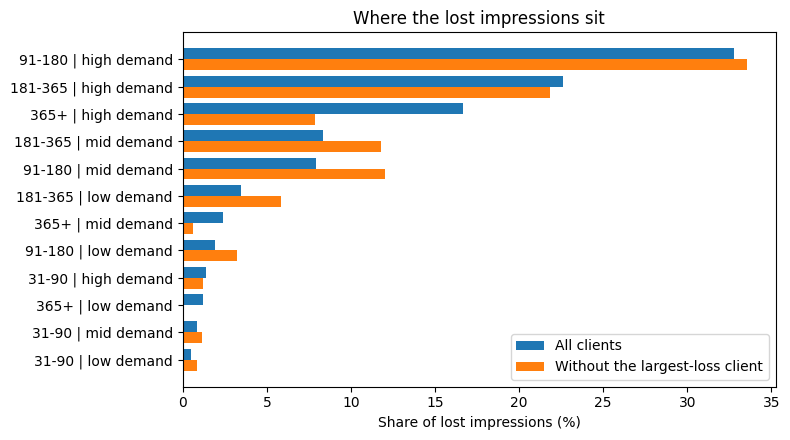

capstone_metrics.json identifier hits: 0
capstone_segments.json identifier hits: 0
per_client_auc.csv identifier hits: 0
capture_top20_per_client.csv identifier hits: 0
persistence_check.csv identifier hits: 0
selection_sensitivity.csv identifier hits: 0
segments_within_client.csv identifier hits: 0
reason_code_check.csv identifier hits: 0
action_summary.csv identifier hits: 0
ranked_pages_sample.csv identifier hits: 0
TOTAL identifier hits: 0


In [16]:
import re, matplotlib.pyplot as plt

def paired(a, b, p, seed=0):
    r = np.random.default_rng(seed)
    diff = (p[a] - p[b]).values
    bs = np.array([r.choice(diff, len(diff), replace=True).mean() for _ in range(5000)])
    lo, hi = np.percentile(bs, [2.5, 97.5])
    return {"mean_diff": round(float(diff.mean()), 4), "ci95": [round(float(lo), 4), round(float(hi), 4)],
            "higher_in": f"{int((diff > 0).sum())}/{len(diff)}"}

p_noB = pc[pc["client"] != "Client B"]
metrics = {
    "data": {"lane": "ai_opportunity", "pages_analysed": int(len(dm)),
             "clients": int(dm["client_hash_id"].nunique()),
             "clients_reported_per_client": int(len(pc)),
             "label": "impressions_last_30d < 0.8 * impressions_prev_30d, prev_30d >= 100",
             "label_rate": round(float(dm["label"].mean()), 4),
             "pages_excluded_not_in_engagement_fix": int((~d["in_ef"]).sum()),
             "excluded_decline_rate": round(float(d.loc[~d["in_ef"], "label"].mean()), 3), "included_decline_rate_in_lane": round(float(dm["label"].mean()), 3)},
    "lane_comparison": json.loads(lane_table.to_json(orient="records")),
    "key_overlap_with_ai_opportunity": json.loads(key_overlap.to_json(orient="records")),
    "mean_client_auc": {k: round(float(pc[k].mean()), 4) for k in cols},
    "mean_client_auc_excluding_client_B": {k: round(float(p_noB[k].mean()), 4) for k in cols},
    "paired_differences_all_clients": {
        "old_window+age vs baseline": paired("old_window+age", "baseline", pc),
        "static vs old_window+age": paired("old_window+age+static", "old_window+age", pc),
        "static vs baseline": paired("old_window+age+static", "baseline", pc),
        "freshness(sensitivity) vs static": paired("+freshness (sensitivity)", "old_window+age+static", pc)},
    "mean_top20_lift_pp": {k: round(float(lt[k].mean() * 100), 2) for k in cols},
    "concentration": {"top1pct_of_pages": round(float(s_.head(int(len(s_) * 0.01)).sum() / tot), 4),
                      "top5pct_of_pages": round(float(s_.head(int(len(s_) * 0.05)).sum() / tot), 4),
                      "top10pct_of_pages": round(float(s_.head(int(len(s_) * 0.10)).sum() / tot), 4),
                      "top_loss_client_share_of_loss": round(float(cl.iloc[0]), 4),
                      "top_loss_client_share_of_pages": round(float((dm["client_hash_id"] == top_loss_client).mean()), 4)},
}
metrics["capture_top20_share_of_lost_impressions"] = {k: round(float(cap[k].mean()), 4) for k in cap.columns if k not in ("client", "n")}
metrics["persistence_check"] = {"clients_later_decline_higher_after_earlier_fall": f"{int((pers['diff'] > 0).sum())}/{len(pers)}",
                                "mean_auc_of_negative_momentum": round(float(pers["AUC_of_-momentum"].mean()), 4)}
metrics["selection_sensitivity_mean_auc"] = {k: round(float(sens[k].mean()), 4) for k in ["baseline_main", "baseline_full", "static_main", "static_full"]}
metrics["review_budget_top20_share_of_lost_impressions"] = round(float(bud["lost_imp"].sum() / ranked["lost_imp"].sum()), 4)
json.dump(metrics, open("work/outputs/capstone_metrics.json", "w"), indent=2)
json.dump(json.loads(seg2.round(4).to_json(orient="records")), open("work/outputs/capstone_segments.json", "w"), indent=2)
pc.round(4).to_csv("work/outputs/per_client_auc.csv", index=False)

# Figure 1: per-client AUC, baseline vs static model
fig, ax = plt.subplots(figsize=(9, 4)); xs = np.arange(len(pc)); w = 0.38
ax.bar(xs - w/2, pc["baseline"], w, label="Baseline rule")
ax.bar(xs + w/2, pc["old_window+age+static"], w, label="Boosting (old-window + age + static)")
ax.axhline(0.5, color="k", ls="--", lw=1); ax.set_ylim(0.4, 0.75)
ax.set_xticks(xs); ax.set_xticklabels(pc["client"], rotation=45, ha="right")
ax.set_ylabel("AUC on held-out client"); ax.legend(); ax.set_title("Per-client AUC (leave-one-client-out)")
plt.tight_layout(); plt.savefig("work/outputs/figs/per_client_auc.png", dpi=150); plt.show()

# Figure 2: share of lost impressions by segment
t = seg2.sort_values("loss_share")
fig, ax = plt.subplots(figsize=(8, 4.5)); ys = np.arange(len(t))
ax.barh(ys + 0.2, t["loss_share"] * 100, 0.4, label="All clients")
ax.barh(ys - 0.2, t["loss_share_without_top_client"] * 100, 0.4, label="Without the largest-loss client")
ax.set_yticks(ys); ax.set_yticklabels(t["segment"]); ax.set_xlabel("Share of lost impressions (%)")
ax.legend(); ax.set_title("Where the lost impressions sit")
plt.tight_layout(); plt.savefig("work/outputs/figs/loss_by_segment.png", dpi=150); plt.show()

# identifier scan of everything saved
bad = 0
for f in ["capstone_metrics.json", "capstone_segments.json", "per_client_auc.csv", "capture_top20_per_client.csv", "persistence_check.csv", "selection_sensitivity.csv", "segments_within_client.csv", "reason_code_check.csv", "action_summary.csv", "ranked_pages_sample.csv"]:
    txt = open("work/outputs/" + f).read()
    hits = re.findall(r"(?:client|content)_[0-9a-f]{8,}", txt)
    bad += len(hits); print(f, "identifier hits:", len(hits))
print("TOTAL identifier hits:", bad)

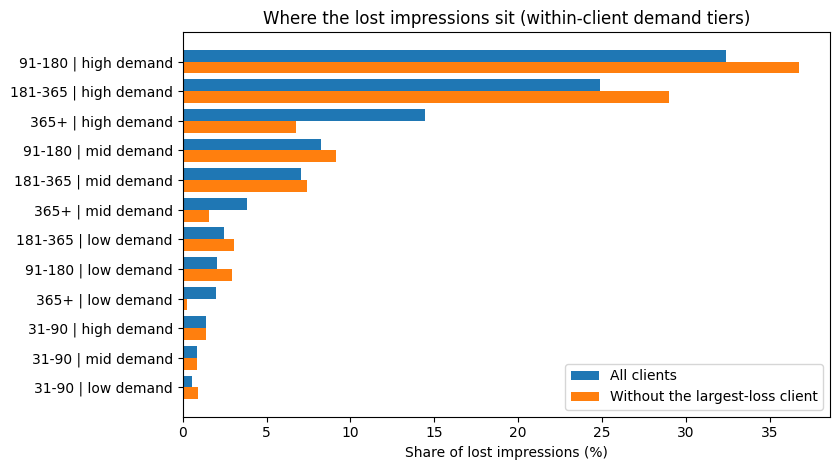

In [17]:
t = seg_w.sort_values("loss_share")
fig, ax = plt.subplots(figsize=(8.5, 4.8)); ys = np.arange(len(t))
ax.barh(ys + 0.2, t["loss_share"] * 100, 0.4, label="All clients")
ax.barh(ys - 0.2, t["loss_share_without_top_client"] * 100, 0.4, label="Without the largest-loss client")
ax.set_yticks(ys); ax.set_yticklabels(t["segment"].str.replace(" (within client)", "", regex=False))
ax.set_xlabel("Share of lost impressions (%)")
ax.set_title("Where the lost impressions sit (within-client demand tiers)")
ax.legend(); plt.tight_layout()
plt.savefig("work/outputs/figs/loss_by_segment_within_client.png", dpi=150); plt.show()

## 6. Limitations

1. **The model does not beat a simple rule, and it is the wrong tool for the editor's goal.** Mean per-client AUC is 0.567 for boosting vs 0.561 for the age-and-demand rule (paired difference +0.006, 95% CI -0.046 to +0.053). Age alone gives about the same top-20% lift (6.3 vs 6.2 points). On lost impressions captured in each client's top 20% of pages, the classifier gets 20.8% (random is 20.0%), the age-and-demand rule 50.9%, and ranking by page impressions 56.1% (section 4b). Adding model risk to impressions does not improve on this (-0.5 points, 95% CI -2.4 to +0.9).
2. **Weak where the value is.** The client with the most pages and 46.9% of lost impressions has an AUC near 0.5 (0.507), so the average hides the case that matters most.
3. **One pair of windows.** Leave-one-client-out tests transfer across clients, not across time. Section 4b's persistence check is the only time-related evidence available.
4. **Sample selection.** 858 pages outside `engagement_fix` were dropped and decline more than the rest (66.9% vs 45.0%). Keeping them raises the model's mean AUC from 0.567 to 0.596 (section 4c), but this probably reflects missing-feature status rather than real signal, because membership in `engagement_fix` may depend on last-window activity. The main analysis therefore excludes them.
5. **Regression to the mean and a broad decline.** Pages are selected on at least 100 previous-window impressions, and 45% of them are labelled declining, so part of the label is noise or a market-wide dip rather than page-specific decay.
6. **Small evaluation set.** Only 10 of 29 clients have at least 100 pages; the smallest have few positive pages, so their AUCs are noisy and the bootstrap over 10 clients has little power.
7. **Concentrated losses.** Lost impressions are heavy-tailed: the top 1% of pages hold 19.8% of the total, the top 5% hold 47.9%, and the top 10% hold 65.6%. One client accounts for 46.9% of lost impressions (37.2% of pages). With within-client demand tiers (section 5b), the 91-180 and 181-365 day high-demand segments remain the largest loss pools (32.4% and 24.9% of lost impressions; 36.7% and 29.0% without the top client), but the 365+ day high-demand segment's share falls from 14.4% to 6.7%, so that segment depends on one client.
8. **Segments are in-sample.** They were defined after seeing the data and use pooled demand terciles, which partly reflect client size. Section 5b repeats them with within-client terciles.
9. **Coarse and possibly late features.** Word count, character count and age are tiers only, and may be measured at the end of the label window. Freshness is only a sensitivity run for that reason.
10. **Observational only.** A high score means a page resembles pages that declined. No claim is made that refreshing it changes its traffic or anything about Google's algorithm.
11. **Scores are not calibrated per client.** The model is trained on other clients, so its scores do not match a held-out client's own decline rate (a client with a 17.7% decline rate receives scores of 0.4-0.6). Scores are reported as a risk score for ranking within a client, never as a probability.
